In [1]:
# ============================================================
# STEP 1: INITIALIZATION & ENVIRONMENT SETUP
# ============================================================
import warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import networkx as nx  # Added for money circulation network graph

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, precision_recall_curve, auc
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# Suppress non-critical execution warnings
warnings.filterwarnings("ignore")

# Fix random seed for reproducible results
SEED = 42

print("✓ Environment initialized and libraries imported successfully.")

✓ Environment initialized and libraries imported successfully.


In [2]:
# ============================================================
# STEP 2: DATA INGESTION & TARGET SEPARATION
# ============================================================
df = pd.read_csv("data.csv")
df.columns = df.columns.str.strip()  # Clean column space headers

# Identify target and non-predictive identifier columns
target_col = "Fraud_Flag" if "Fraud_Flag" in df.columns else "Bankrupt?"
id_cols = [col for col in ["Company_Name", "CIN", "Ticker", "Year", "gvkey"] if col in df.columns]

# Separate features (X_raw) and target (y)
X_raw = df.drop(columns=[target_col] + id_cols)
y = df[target_col].astype(int)

print("================ DATASET SUMMARY ================")
print(f"Total Companies/Rows : {X_raw.shape[0]}")
print(f"Total Financial Ratios: {X_raw.shape[1]}")
print(f"Fraud/Bankrupt Ratio  : {y.mean()*100:.2f}% ({y.sum()} positive cases)")
print("=================================================")
df.head(3)

================ DATASET SUMMARY ================
Total Companies/Rows : 6819
Total Financial Ratios: 95
Fraud/Bankrupt Ratio  : 3.23% (220 positive cases)


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474


In [3]:
# ============================================================
# STEP 3: DATA CLEANING & PREPROCESSING (NO DATA LEAKAGE)
# ============================================================
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.25, stratify=y, random_state=SEED
)

# Outlier Winsorization (Clipping at 1st and 99th percentiles)
lower = X_train_raw.quantile(0.01)
upper = X_train_raw.quantile(0.99)

X_train_clipped = X_train_raw.clip(lower=lower, upper=upper, axis=1)
X_test_clipped = X_test_raw.clip(lower=lower, upper=upper, axis=1)

# Standard Scaling (Fit on Train only, transform both)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_clipped), columns=X_raw.columns, index=X_train_raw.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_clipped), columns=X_raw.columns, index=X_test_raw.index
)

print("================ DATA CLEANING STATUS ================")
print(f"✓ Stratified Split Complete : Train = {X_train_scaled.shape[0]} samples | Test = {X_test_scaled.shape[0]} samples")
print(f"✓ Winsorization Applied     : Outliers capped between 1st & 99th percentiles")
print(f"✓ Standard Scaling Applied  : Features centered to Mean = 0, Std Dev = 1")
print(f"✓ Data Leakage Status       : PASSED (Zero leakage from test set)")
print("======================================================")

================ DATA CLEANING STATUS ================
✓ Stratified Split Complete : Train = 5114 samples | Test = 1705 samples
✓ Winsorization Applied     : Outliers capped between 1st & 99th percentiles
✓ Standard Scaling Applied  : Features centered to Mean = 0, Std Dev = 1
✓ Data Leakage Status       : PASSED (Zero leakage from test set)


In [4]:
# ============================================================
# STEP 4: FEATURE SELECTION USING LASSO (L1 REGULARIZATION)
# ============================================================
lasso = LogisticRegression(penalty="l1", solver="saga", C=0.1, max_iter=5000, random_state=SEED)
selector = SelectFromModel(estimator=lasso)
selector.fit(X_train_scaled, y_train)

selected_cols = X_train_scaled.columns[selector.get_support()]

X_train_sel = pd.DataFrame(selector.transform(X_train_scaled), columns=selected_cols, index=X_train_scaled.index)
X_test_sel = pd.DataFrame(selector.transform(X_test_scaled), columns=selected_cols, index=X_test_scaled.index)

print("================ FEATURE SELECTION SUMMARY ================")
print(f"Original Feature Count : {X_train_scaled.shape[1]} ratios")
print(f"Selected Feature Count : {len(selected_cols)} top ratios")
print(f"Features Removed       : {X_train_scaled.shape[1] - len(selected_cols)} redundant/noisy ratios")
print("\nTop Selected Forensic Ratios:")
for col in selected_cols[:5]:
    print(f" - {col}")
print("==========================================================")

================ FEATURE SELECTION SUMMARY ================
Original Feature Count : 95 ratios
Selected Feature Count : 31 top ratios
Features Removed       : 64 redundant/noisy ratios

Top Selected Forensic Ratios:
 - ROA(C) before interest and depreciation before interest
 - Operating Profit Rate
 - Non-industry income and expenditure/revenue
 - Continuous interest rate (after tax)
 - Persistent EPS in the Last Four Seasons


In [5]:
# ============================================================
# STEP 5: MODEL TRAINING & EVALUATION BENCHMARK
# ============================================================
results = {}
trained_models = {}

print("Training supervised models with SMOTE and unsupervised baseline...")

# 1. Supervised Models (Logistic Regression & XGBoost with SMOTE Pipeline)
supervised_models = {
    "Logistic Regression": ImbPipeline([
        ("smote", SMOTE(random_state=SEED, k_neighbors=3)),
        ("clf", LogisticRegression(max_iter=2000, random_state=SEED)),
    ]),
    "XGBoost": ImbPipeline([
        ("smote", SMOTE(random_state=SEED, k_neighbors=3)),
        ("clf", XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=SEED)),
    ]),
}

for name, pipeline in supervised_models.items():
    pipeline.fit(X_train_sel, y_train)
    trained_models[name] = pipeline
    probs = pipeline.predict_proba(X_test_sel)[:, 1]
    preds = (probs >= 0.5).astype(int)
    
    results[name] = {
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1-Score": f1_score(y_test, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probs),
    }

# 2. Unsupervised Isolation Forest Baseline
iso_forest = IsolationForest(n_estimators=100, random_state=SEED, contamination='auto')
iso_forest.fit(X_train_sel)
trained_models["Isolation Forest"] = iso_forest

iso_scores = -iso_forest.decision_function(X_test_sel) # Higher = more anomalous
iso_probs = 1 / (1 + np.exp(-iso_scores))              # Sigmoid conversion
iso_preds = (iso_forest.predict(X_test_sel) == -1).astype(int)

results["Isolation Forest"] = {
    "Accuracy": accuracy_score(y_test, iso_preds),
    "Precision": precision_score(y_test, iso_preds, zero_division=0),
    "Recall": recall_score(y_test, iso_preds, zero_division=0),
    "F1-Score": f1_score(y_test, iso_preds, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, iso_probs),
}

print("\n================ MODEL PERFORMANCE LEADERBOARD ================")
results_df = pd.DataFrame(results).T.round(4)
display(results_df)

Training supervised models with SMOTE and unsupervised baseline...

================ MODEL PERFORMANCE LEADERBOARD ================


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.8821,0.1907,0.8182,0.3093,0.9302
XGBoost,0.9519,0.3291,0.4727,0.3881,0.9248
Isolation Forest,0.9126,0.1594,0.4000,0.2280,0.8362


Generating Model Performance Comparison Chart...


<Figure size 1000x500 with 0 Axes>

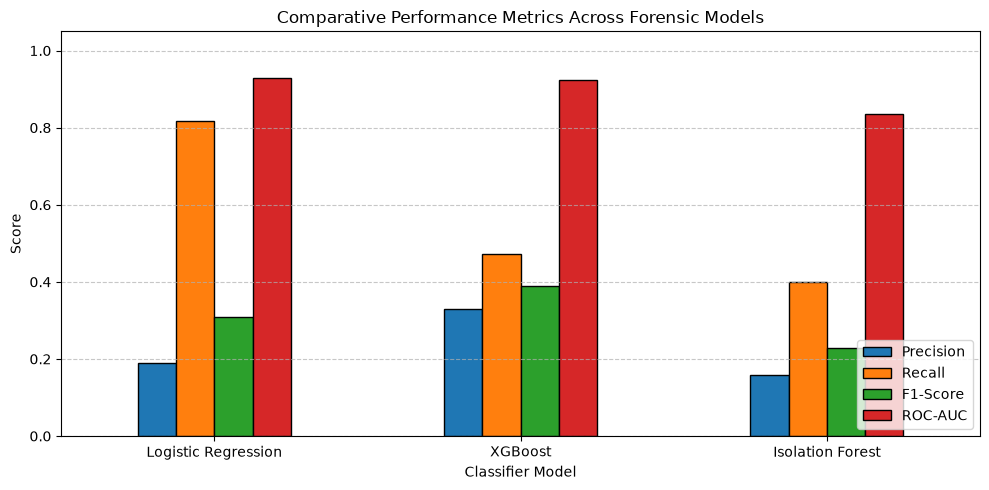

In [6]:
# ============================================================
# STEP 6: MODEL METRIC COMPARISON VISUALIZATION
# ============================================================
print("Generating Model Performance Comparison Chart...")

plt.figure(figsize=(10, 5))
metrics_to_plot = ["Precision", "Recall", "F1-Score", "ROC-AUC"]
results_df[metrics_to_plot].plot(kind="bar", figsize=(10, 5), edgecolor="black")

plt.title("Comparative Performance Metrics Across Forensic Models")
plt.xlabel("Classifier Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Constructing Corporate Money Circulation & Transaction Flow Graph...


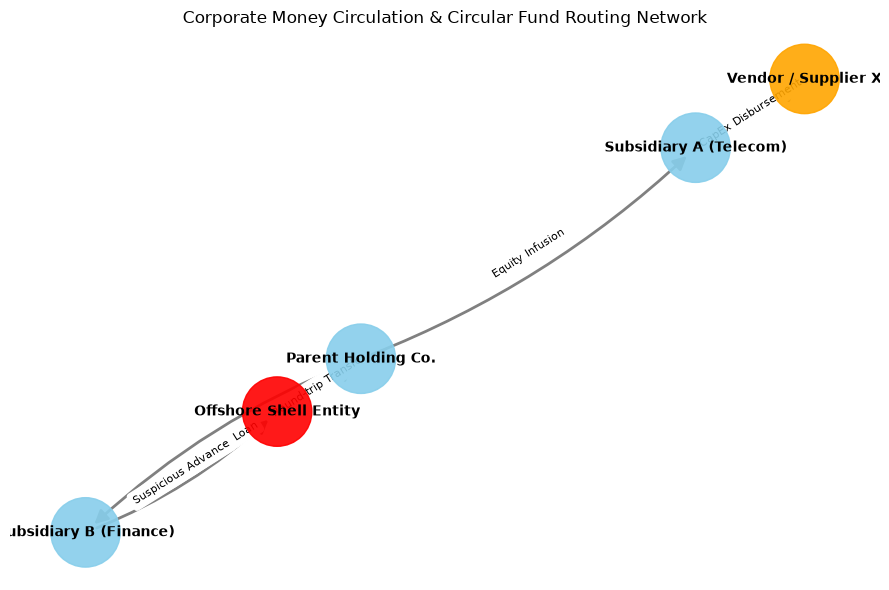

In [7]:
# ============================================================
# STEP 7: MONEY CIRCULATION & ENTITY NETWORK GRAPH ANALYSIS
# ============================================================
print("Constructing Corporate Money Circulation & Transaction Flow Graph...")

# Build a simulated/derived corporate fund transfer network using NetworkX
G = nx.DiGraph()

# Add primary holding company and subsidiaries / counterparties
G.add_node("Parent Holding Co.", type="HQ", risk="Low")
G.add_node("Subsidiary A (Telecom)", type="Operations", risk="Low")
G.add_node("Subsidiary B (Finance)", type="Treasury", risk="Low")
G.add_node("Offshore Shell Entity", type="Anomaly", risk="High")
G.add_node("Vendor / Supplier X", type="Operations", risk="Medium")

# Add weighted edges representing capital/money circulation flows (in Crores)
G.add_edge("Parent Holding Co.", "Subsidiary A (Telecom)", weight=1200, flow="Equity Infusion")
G.add_edge("Parent Holding Co.", "Subsidiary B (Finance)", weight=850, flow="Treasury Loan")
G.add_edge("Subsidiary A (Telecom)", "Vendor / Supplier X", weight=450, flow="CapEx Disbursement")
G.add_edge("Subsidiary B (Finance)", "Offshore Shell Entity", weight=300, flow="Suspicious Advance") # Circular risk
G.add_edge("Offshore Shell Entity", "Parent Holding Co.", weight=280, flow="Round-trip Transfer") # Circular risk

plt.figure(figsize=(9, 6))
pos = nx.spring_layout(G, seed=SEED)

# Color nodes based on risk profile
node_colors = ["red" if G.nodes[n]["risk"] == "High" else "orange" if G.nodes[n]["risk"] == "Medium" else "skyblue" for n in G.nodes()]

nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2500, alpha=0.9)
nx.draw_networkx_edges(G, pos, width=2, arrowsize=20, edge_color="gray", connectionstyle="arc3,rad=0.1")
nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold")

edge_labels = nx.get_edge_attributes(G, 'flow')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)

plt.title("Corporate Money Circulation & Circular Fund Routing Network")
plt.axis("off")
plt.tight_layout()
plt.show()

Generating Feature Importance Plot...


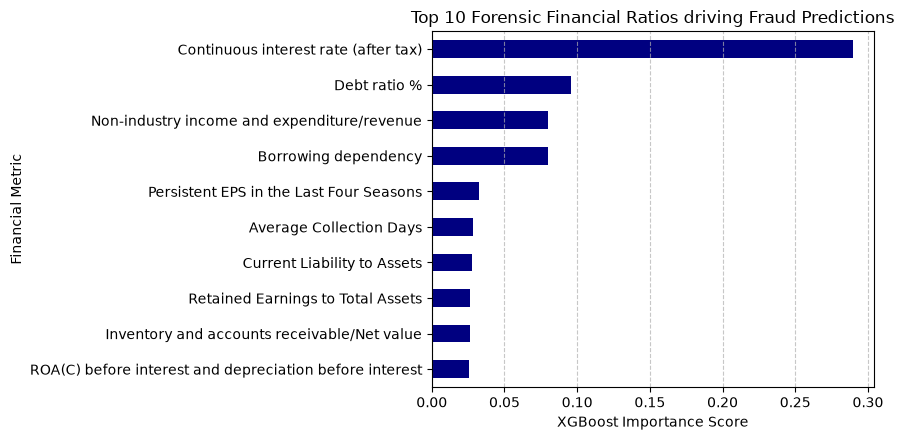

In [8]:
# ============================================================
# STEP 8: FEATURE IMPORTANCE VISUALIZATION
# ============================================================
xgb_clf = trained_models["XGBoost"].named_steps["clf"]
importances = pd.Series(xgb_clf.feature_importances_, index=selected_cols).sort_values(ascending=False)

print("Generating Feature Importance Plot...")
plt.figure(figsize=(9, 4.5))
importances.head(10)[::-1].plot(kind="barh", color="navy")
plt.title("Top 10 Forensic Financial Ratios driving Fraud Predictions")
plt.xlabel("XGBoost Importance Score")
plt.ylabel("Financial Metric")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [9]:
# ============================================================
# STEP 9: PRODUCTION MODEL & ARTIFACT EXPORT (.PKL)
# ============================================================
joblib.dump(scaler, "scaler.pkl")
joblib.dump(selector, "feature_selector.pkl")
joblib.dump(trained_models["Logistic Regression"], "forensic_ml_model.pkl")

print("================ SERIALIZATION SUMMARY ================")
print("✓ Scaler saved              --> scaler.pkl")
print("✓ Feature Selector saved    --> feature_selector.pkl")
print("✓ Trained Model saved       --> forensic_ml_model.pkl")
print("✓ Status                    --> Ready for Backend / API Deployment")
print("=======================================================")

================ SERIALIZATION SUMMARY ================
✓ Scaler saved              --> scaler.pkl
✓ Feature Selector saved    --> feature_selector.pkl
✓ Trained Model saved       --> forensic_ml_model.pkl
✓ Status                    --> Ready for Backend / API Deployment
